In [27]:
import numpy as np
import pandas as pd
from sklearn import preprocessing

import warnings
warnings.filterwarnings('ignore')

In [28]:
data1=pd.read_csv('Iris.csv')
data1

,sepal length,sepal width,petal length,petal width,class
0,4.3,3.0,1.1,0.1,Iris-setosa
1,4.4,2.9,1.4,0.2,Iris-setosa
2,4.4,3.0,1.3,0.2,Iris-setosa
3,4.4,3.2,1.3,0.2,Iris-setosa
4,4.5,2.3,1.3,0.3,Iris-setosa
...,...,...,...,...,...
145,7.7,3.8,6.7,2.2,Iris-virginica
146,7.7,2.6,6.9,2.3,Iris-virginica
147,7.7,2.8,6.7,2.0,Iris-virginica
148,7.7,3.0,6.1,2.3,Iris-virginica


In [29]:
data1.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal length  150 non-null    float64
 1   sepal width   150 non-null    float64
 2   petal length  150 non-null    float64
 3   petal width   150 non-null    float64
 4   class         150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB


In [30]:
data1['class'].unique()

<ArrowStringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

In [31]:
data1['class'].value_counts()

class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [32]:
data1.isna().sum()

sepal length    0
sepal width     0
petal length    0
petal width     0
class           0
dtype: int64

In [33]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

data1['class'] = le.fit_transform(data1['class'])
data1

,sepal length,sepal width,petal length,petal width,class
0,4.3,3.0,1.1,0.1,0
1,4.4,2.9,1.4,0.2,0
2,4.4,3.0,1.3,0.2,0
3,4.4,3.2,1.3,0.2,0
4,4.5,2.3,1.3,0.3,0
...,...,...,...,...,...
145,7.7,3.8,6.7,2.2,2
146,7.7,2.6,6.9,2.3,2
147,7.7,2.8,6.7,2.0,2
148,7.7,3.0,6.1,2.3,2


In [34]:

x=data1.iloc[:,0:4]

y=data1.iloc[:,4]


In [35]:
x

,sepal length,sepal width,petal length,petal width
0,4.3,3.0,1.1,0.1
1,4.4,2.9,1.4,0.2
2,4.4,3.0,1.3,0.2
3,4.4,3.2,1.3,0.2
4,4.5,2.3,1.3,0.3
...,...,...,...,...
145,7.7,3.8,6.7,2.2
146,7.7,2.6,6.9,2.3
147,7.7,2.8,6.7,2.0
148,7.7,3.0,6.1,2.3


In [36]:
y

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Name: class, Length: 150, dtype: int64

In [37]:

minmax=preprocessing.MinMaxScaler(feature_range=(0,1))

x = minmax.fit_transform(x)

In [38]:
x

array([[0.        , 0.41666667, 0.01694915, 0.        ],
       [0.02777778, 0.375     , 0.06779661, 0.04166667],
       [0.02777778, 0.41666667, 0.05084746, 0.04166667],
       [0.02777778, 0.5       , 0.05084746, 0.04166667],
       [0.05555556, 0.125     , 0.05084746, 0.08333333],
       [0.08333333, 0.45833333, 0.08474576, 0.04166667],
       [0.08333333, 0.58333333, 0.06779661, 0.08333333],
       [0.08333333, 0.66666667, 0.        , 0.04166667],
       [0.08333333, 0.5       , 0.06779661, 0.04166667],
       [0.11111111, 0.5       , 0.05084746, 0.04166667],
       [0.11111111, 0.5       , 0.10169492, 0.04166667],
       [0.13888889, 0.58333333, 0.10169492, 0.04166667],
       [0.13888889, 0.41666667, 0.06779661, 0.        ],
       [0.13888889, 0.58333333, 0.15254237, 0.04166667],
       [0.13888889, 0.45833333, 0.10169492, 0.04166667],
       [0.13888889, 0.41666667, 0.06779661, 0.08333333],
       [0.16666667, 0.41666667, 0.06779661, 0.04166667],
       [0.16666667, 0.45833333,

In [39]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.3)


In [40]:
from sklearn.neighbors import KNeighborsClassifier

clf = KNeighborsClassifier()

In [41]:
clf.fit(x_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [42]:
#Predict on test data
y_pred=clf.predict(x_test)

In [43]:
print("Actual breast cancer : ")

print(y_test.values)

Actual breast cancer : 
[1 0 0 0 1 0 1 1 1 1 2 2 1 1 2 2 2 2 0 2 0 1 0 0 0 2 2 1 0 0 2 0 2 0 2 0 2
 2 1 0 2 1 2 0 1]


In [44]:
print("\nPredicted breast cancer : ")

print(y_pred)


Predicted breast cancer : 
[1 0 0 0 1 0 1 1 1 1 2 2 1 1 2 2 2 2 0 2 0 1 0 0 0 2 2 1 0 0 2 0 2 0 1 0 2
 2 1 0 2 2 2 0 1]


In [45]:
from sklearn.metrics import accuracy_score, recall_score,precision_score 
print("\nAccuracy score: %f" %(accuracy_score(y_test,y_pred) * 100))



Accuracy score: 95.555556


In [46]:
from sklearn import metrics

print(metrics.classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        16
           1      0.923     0.923     0.923        13
           2      0.938     0.938     0.938        16

    accuracy                          0.956        45
   macro avg      0.954     0.954     0.954        45
weighted avg      0.956     0.956     0.956        45



In [47]:
print(metrics.confusion_matrix(y_test, y_pred))

[[16  0  0]
 [ 0 12  1]
 [ 0  1 15]]


In [48]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

k_values = [i for i in range (1,13)]
scores = []

scaler = StandardScaler()
X = scaler.fit_transform(x)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, x, y, cv=5)
   # print(scores)
    scores.append(np.mean(score))
    
print(scores)

[np.float64(0.9), np.float64(0.8800000000000001), np.float64(0.9266666666666667), np.float64(0.9333333333333333), np.float64(0.9266666666666667), np.float64(0.9266666666666667), np.float64(0.9333333333333333), np.float64(0.9466666666666667), np.float64(0.9333333333333333), np.float64(0.9466666666666667), np.float64(0.9333333333333333), np.float64(0.9400000000000001)]


Text(0, 0.5, 'Accuracy Score')

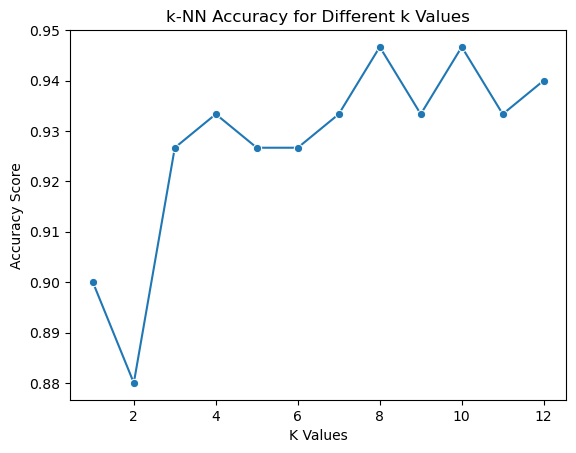

In [49]:
import seaborn as sns 
import matplotlib.pyplot as plt

sns.lineplot(x = k_values, y = scores, marker = 'o')

plt.title("k-NN Accuracy for Different k Values")
plt.xlabel("K Values")
plt.ylabel("Accuracy Score")